# **Mineração de Dados Aplicada a Pesquisa Nacional de Saúde de 2019 - Agrupamento**

Neste notebook, é aplicado técnicas de clustering à base de dados da Pesquisa Nacional de Saúde de 2019 para analisar padrões em casos de dor crônica na coluna.

## **Etapa 1 - Importação de Bibliotecas e Base de Dados**

Nesta etapa, realizamos a importação das bibliotecas (pacotes) que serão utilizadas para a análise e agrupamento dos dados. Cada biblioteca oferece funcionalidades específicas que nos auxiliarão na manipulação, visualização e análise dos dados.

**Funcionalidades de Cada Biblioteca:**

* **NumPy:** Operações numéricas, criação de arrays e matrizes.
* **Pandas:** Manipulação e análise de dados, criação e manipulação de DataFrames.
* **Seaborn:** Visualização de dados, criação de gráficos estatísticos.
* **NetworkX:** Criação e manipulação de grafos, visualização de relações entre dados.
* **Matplotlib:** Criação de gráficos estáticos, oferece um conjunto completo de ferramentas para visualização de dados.
* **Plotly:** Criação de gráficos interativos, oferecendo uma ampla variedade de visualizações.
* **Itertools:** Geração de todas as combinações possíveis de elementos em um iterável.
* **Scikit-learn:**
  * **KMeans:** Implementação do algoritmo de clustering K-means.
  * **PCA:** Realização de Análise de Componentes Principais (PCA).
  * **silhouette_score:** Cálculo da métrica Silhouette para avaliar a qualidade dos clusters.
  * **silhouette_samples:** Cálculo dos coeficientes de silhouette para cada amostra.
  * **MinMaxScaler:** Escalonamento dos dados.

In [1]:
import numpy as np # Biblioteca fundamental para operações numéricas em Python, como criação de arrays e matrizes.
import pandas as pd # Biblioteca para manipulação e análise de dados, utilizada para criar e manipular DataFrames.
import seaborn as sns # Biblioteca para visualização de dados, oferecendo uma interface de alto nível para criar gráficos estatísticos.
import networkx as nx # Biblioteca para criação e manipulação de grafos, útil para visualizar relações entre dados.
import matplotlib.cm as cm # Biblioteca para criação de mapas de cores personalizados.
import plotly.express as px # Biblioteca para criação de gráficos interativos, oferecendo uma ampla variedade de visualizações.
import matplotlib.pyplot as plt # Biblioteca para criação de gráficos estáticos, oferecendo um conjunto completo de ferramentas para visualização de dados.
import plotly.graph_objects as go # Biblioteca para criação de gráficos interativos complexos.
from itertools import combinations # Biblioteca para gerar todas as combinações possíveis de elementos em um iterável.
from sklearn.cluster import KMeans # Biblioteca para implementar o algoritmo de clustering K-means.
from sklearn.decomposition import PCA # Biblioteca para realizar Análise de Componentes Principais (PCA), uma técnica de redução de dimensionalidade.
from sklearn.metrics import silhouette_score # Biblioteca para calcular a métrica Silhouette, utilizada para avaliar a qualidade dos clusters.
from sklearn.metrics import silhouette_samples # Biblioteca para calcular os coeficientes de silhouette para cada amostra.
from sklearn.preprocessing import MinMaxScaler # Biblioteca para escalonar os dados, colocando todas as features em uma mesma escala.
print('Bibliotecas carregadas com sucesso')

Bibliotecas carregadas com sucesso


In [2]:
# importa o arquivo e guarda em um dataframe do Pandas
dfDataBaseB = pd.read_excel( '/content/DataBaseProcessedBinary.xlsx')
dfDataBaseR = pd.read_excel( '/content/DataBaseProcessedReal.xlsx')
print('Dados importados com sucesso!')

Dados importados com sucesso!


In [3]:
def print_shape(name, df):
    num_linhas, num_colunas = df.shape
    print(f'{name}: \nLinhas: {num_linhas}\nVariáveis: {num_colunas}')

    if 'Serviço de Saúde' in df.columns:
        uso_servico = df['Serviço de Saúde'].value_counts().to_dict()
        usados = uso_servico.get(1, 0)
        nao_usados = uso_servico.get(0, 0)
        print(f'Usaram o serviço de saúde (1): {usados}')
        print(f'Não usaram o serviço de saúde (0): {nao_usados}\n')
    else:
        print('Coluna "Serviço de Saúde" não encontrada no DataFrame.\n')

print_shape('Dados PNS - Pre-Processamento - Binários', dfDataBaseB)
print_shape('Dados PNS - Pre-Processamento - Reais', dfDataBaseR)


Dados PNS - Pre-Processamento - Binários: 
Linhas: 87678
Variáveis: 161
Usaram o serviço de saúde (1): 18267
Não usaram o serviço de saúde (0): 69411

Dados PNS - Pre-Processamento - Reais: 
Linhas: 87678
Variáveis: 61
Usaram o serviço de saúde (1): 18267
Não usaram o serviço de saúde (0): 69411



## **Etapa 2 - Filtro da base dados**

Nesta etapa, filtramos a base de dados para reter apenas informações relevantes, preparando-a para a aplicação de diversos algoritmos de mineração de dados, focados em análises e visualizações eficazes relacionadas à dor crônica na coluna.

### **2.1 - Listagem de Colunas**

In [4]:
# Convertendo a lista de colunas em uma string e imprimindo
print(',\n'.join(dfDataBaseB.columns))
print('\n-------------------------\n')
print(',\n'.join(dfDataBaseR.columns))

Cadastro UBS,
Agente Comunitário,
Ler e Escrever,
Escola,
Trabalha,
Plano de Saúde,
Serviço de Saúde,
Internação,
Álcool,
Exercício Físico,
Tabaco,
Colesterol Alto,
AVC ou Derrame,
Asma,
Artrite ou Reumatismo,
Dor na Coluna,
DORT,
Depressão,
Hipertensão,
Diabetes,
Cardiopatia,
Câncer,
Insuficiência Renal Crônica,
Doença Mental,
Doença Crônica no Pulmão,
Região Norte,
Região Nordeste,
Região Centro Oeste,
Região Sudeste,
Região Sul,
Urbano,
Rural,
EF Incompleto,
SP Incompleto,
EM Incompleto,
EF Completo,
SP Completo,
EM Completo,
Sem Instrução,
Per Capita 1,
Per Capita 2,
Per Capita 3,
Per Capita 4,
Per Capita 5,
Per Capita 6,
Per Capita 7,
Homem,
Mulher,
Idade 18 a 29,
Idade 30 a 39,
Idade 40 a 49,
Idade 50 a 59,
Idade 60 a 69,
Idade 70 a 79,
Idade 80 a 89,
Idade 90 a 99,
Idade 100 a 104,
Raça 1,
Raça 2,
Raça 3,
Raça 4,
Raça 5,
Casado,
Solteiro,
Viúvo,
Divorciado,
Saúde Regular,
Saúde Muito Ruim,
Saúde Bom,
Saúde Muito Bom,
Saúde Ruim,
Baixo Peso,
Peso Normal,
Sobrepeso,
Obesidade,
Pes

### **2.2 - Seleção de Total - Binários**

In [5]:
# Lista das colunas
todasColunas = [
  "Cadastro UBS",
  "Agente Comunitário",
  "Ler e Escrever",
  "Escola",
  "Trabalha",
  "Plano de Saúde",
  "Serviço de Saúde",
  "Internação",
  "Álcool",
  "Exercício Físico",
  "Tabaco",
  "Colesterol Alto",
  "AVC ou Derrame",
  "Asma",
  "Artrite ou Reumatismo",
  "Dor na Coluna",
  "DORT",
  "Depressão",
  "Hipertensão",
  "Diabetes",
  "Cardiopatia",
  "Câncer",
  "Insuficiência Renal Crônica",
  "Doença Mental",
  "Doença Crônica no Pulmão",
  "Idade 18 a 29",
  "Idade 30 a 39",
  "Idade 40 a 49",
  "Idade 50 a 59",
  "Idade 60 a 69",
  "Idade 70 a 79",
  "Idade 80 a 89",
  "Idade 90 a 99",
  "Idade 100 a 104",
  "Raça 1",
  "Raça 2",
  "Raça 3",
  "Raça 4",
  "Raça 5",
  "Peso 30 a 56",
  "Peso 57 a 82",
  "Peso 83 a 108",
  "Peso 109 a 134",
  "Peso 135 a 160",
  "Altura 129 a 142",
  "Altura 143 a 156",
  "Altura 157 a 170",
  "Altura 171 a 184",
  "Altura 185 a 199",
  "Baixo Peso",
  "Peso Normal",
  "Sobrepeso",
  "Per Capita 1",
  "Per Capita 2",
  "Per Capita 3",
  "Per Capita 4",
  "Per Capita 5",
  "Per Capita 6",
  "Per Capita 7",
  "Urbano",
  "Rural",
  "Homem",
  "Mulher",
  "EF Incompleto",
  "SP Incompleto",
  "EM Incompleto",
  "EF Completo",
  "SP Completo",
  "EM Completo",
  "Sem Instrução",
  "Casado",
  "Solteiro",
  "Viúvo",
  "Divorciado",
  "Região Norte",
  "Região Nordeste",
  "Região Centro Oeste",
  "Região Sudeste",
  "Região Sul",
  "Saúde Regular",
  "Saúde Muito Ruim",
  "Saúde Bom",
  "Saúde Muito Bom",
  "Saúde Ruim",
  "Dor na Coluna Não Limita",
  "Dor na Coluna Limita Pouco",
  "Dor na Coluna Limita Moderadamente",
  "Dor na Coluna Limita Intensamente",
  "Dor na Coluna Limita Muito Intensamente",
  "Depressão Não Limita",
  "Depressão Limita Pouco",
  "Depressão Limita Moderadamente",
  "Depressão Limita Intensamente",
  "Depressão Limita Muito Intensamente",
  "Doença Mental Não Limita",
  "Doença Mental Limita Pouco",
  "Doença Mental Limita Moderadamente",
  "Doença Mental Limita Intensamente",
  "Doença Mental Limita Muito Intensamente",
  "Doença do Pulmão Não Limita",
  "Doença do Pulmão Limita Pouco",
  "Doença do Pulmão Limita Moderadamente",
  "Doença do Pulmão Limita Intensamente",
  "Doença do Pulmão Limita Muito Intensamente",
  "Câncer Não Limita",
  "Câncer Limita Pouco",
  "Câncer Limita Moderadamente",
  "Câncer Limita Intensamente",
  "Câncer Limita Muito Intensamente",
  "Insuficiência Renal Não Limita",
  "Insuficiência Renal Limita Pouco",
  "Insuficiência Renal Limita Moderadamente",
  "Insuficiência Renal Limita Intensamente",
  "Insuficiência Renal Limita Muito Intensamente",
  "Hipertensão Não Limita",
  "Hipertensão Limita Pouco",
  "Hipertensão Limita Moderadamente",
  "Hipertensão Limita Intensamente",
  "Hipertensão Limita Muito Intensamente",
  "Diabetes Não Limita",
  "Diabetes Limita Pouco",
  "Diabetes Limita Moderadamente",
  "Diabetes Limita Intensamente",
  "Diabetes Limita Muito Intensamente",
  "Cardiopatia Não Limita",
  "Cardiopatia Limita Pouco",
  "Cardiopatia Limita Moderadamente",
  "Cardiopatia Limita Intensamente",
  "Cardiopatia Limita Muito Intensamente",
  "AVC ou Derrame Não Limita",
  "AVC ou Derrame Limita Pouco",
  "AVC ou Derrame Limita Moderadamente",
  "AVC ou Derrame Limita Intensamente",
  "AVC ou Derrame Limita Muito Intensamente",
  "Asma Não Limita",
  "Asma Limita Pouco",
  "Asma Limita Moderadamente",
  "Asma Limita Intensamente",
  "Asma Limita Muito Intensamente",
  "Artrite ou Reumatismo Não Limita",
  "Artrite ou Reumatismo Limita Pouco",
  "Artrite ou Reumatismo Limita Moderadamente",
  "Artrite ou Reumatismo Limita Intensamente",
  "Artrite ou Reumatismo Limita Muito Intensamente",
  "DORT Não Limita",
  "DORT Limita Pouco",
  "DORT Limita Moderadamente",
  "DORT Limita Intensamente",
  "DORT Limita Muito Intensamente",
  "Grupo Cardiovascular",
  "Grupo Metabólico",
  "Grupo Respiratório",
  "Grupo Artrite",
  "Grupo DORT",
  "Grupo Mental",
  "Grupo Depressão",
  "Grupo Pulmonar",
  "Grupo Renal",
  "Grupo Oncológico",
  "Obesidade",
  "Peso Amostral"
]

# Criando um novo DataFrame com apenas as colunas de interesse
dfGeralB = dfDataBaseB[todasColunas].copy()

# Substituindo todos os valores NaN por 0
dfGeralB.fillna(0, inplace=True)

# Exibir as primeiras linhas do dataframe filtrado
dfGeralB.head(10)

,Cadastro UBS,Agente Comunitário,Ler e Escrever,Escola,Trabalha,Plano de Saúde,Serviço de Saúde,Internação,Álcool,Exercício Físico,...,Grupo Respiratório,Grupo Artrite,Grupo DORT,Grupo Mental,Grupo Depressão,Grupo Pulmonar,Grupo Renal,Grupo Oncológico,Obesidade,Peso Amostral
0,1,1,1,0,1,0,0,0,0,1,...,0,1,0,0,1,0,0,0,0,9.000088e-09
1,1,0,1,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9.000087e-09
2,1,1,1,0,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,9.000087e-09
3,1,0,0,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,9.000087e-09
4,1,0,1,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,9.000087e-09
5,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9.000087e-09
6,1,0,1,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,9.000087e-09
7,1,0,1,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,9.000087e-09
8,0,0,1,0,1,1,1,0,1,1,...,0,0,0,0,0,0,0,0,0,9.000087e-09
9,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9.000087e-09


### **2.3 - Seleção de Total - Reais**

In [6]:
# Lista das colunas
todasColunas = [
  "UF",
  "Zona",
  "Grau de Ensino",
  "Renda",
  "Cadastro UBS",
  "Agente Comunitário",
  "Sexo",
  "Idade",
  "Raça",
  "Estado Civil",
  "Ler e Escrever",
  "Escola",
  "Trabalha",
  "Plano de Saúde",
  "Estado de Saúde",
  "Serviço de Saúde",
  "Internação",
  "Álcool",
  "Exercício Físico",
  "Tabaco",
  "Peso",
  "Altura",
  "Colesterol Alto",
  "AVC ou Derrame",
  "AVC ou Derrame Limita Atividades",
  "Asma",
  "Asma Limita Atividades",
  "Artrite ou Reumatismo",
  "Artrite ou Reumatismo Limita Atividades",
  "Dor na Coluna",
  "Dor na Coluna Limita Atividades",
  "DORT",
  "DORT Limita Atividades",
  "Depressão",
  "Depressão Limita Atividades",
  "Hipertensão",
  "Hipertensão Limita Atividades",
  "Diabetes",
  "Diabetes Limita Atividades",
  "Cardiopatia",
  "Cardiopatia Limita Atividades",
  "Câncer",
  "Câncer Limita Atividades",
  "Insuficiência Renal Crônica",
  "Insuficiência Renal Limita Atividades",
  "Doença Mental",
  "Doença Mental Limita Atividades",
  "Doença Crônica no Pulmão",
  "Doença Crônica no Pulmão Limita Atividades",
  "Peso Amostral",
  "Grupo Metabólico",
  "Grupo Respiratório",
  "Grupo Artrite",
  "Grupo DORT",
  "Grupo Mental",
  "Grupo Depressão",
  "Grupo Pulmonar",
  "Grupo Renal",
  "Grupo Oncológico",
  "Grupo Cardiovascular",
  "IMC"
]

# Criando um novo DataFrame com apenas as colunas de interesse
dfGeralR = dfDataBaseR[todasColunas].copy()

# Substituindo todos os valores NaN por 0
dfGeralR.fillna(0, inplace=True)

# Exibir as primeiras linhas do dataframe filtrado
dfGeralR.head(10)

,UF,Zona,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Sexo,Idade,Raça,Estado Civil,...,Grupo Respiratório,Grupo Artrite,Grupo DORT,Grupo Mental,Grupo Depressão,Grupo Pulmonar,Grupo Renal,Grupo Oncológico,Grupo Cardiovascular,IMC
0,1,1,1,2,1,1,2,55,1,2,...,0,1,0,0,1,0,0,0,1,28.537455
1,1,1,3,2,1,0,2,19,4,1,...,0,0,0,0,0,0,0,0,0,28.133657
2,1,1,4,3,1,1,2,45,3,1,...,0,0,0,0,0,0,0,0,0,32.049948
3,1,1,0,2,1,0,2,58,3,3,...,0,0,0,0,0,0,0,0,0,22.151023
4,1,1,5,1,1,0,2,28,4,1,...,0,0,0,0,0,0,0,0,0,17.755682
5,1,1,1,3,1,0,1,81,4,1,...,0,0,0,0,0,0,0,0,1,26.753864
6,1,1,4,-1,1,0,2,41,4,2,...,0,0,0,0,0,0,0,0,0,25.951557
7,1,1,4,1,1,0,2,38,1,1,...,0,0,0,0,0,0,0,0,0,24.654832
8,1,1,3,3,0,-1,1,33,4,1,...,0,0,0,0,0,0,0,0,0,27.041644
9,1,1,1,-1,1,0,1,81,4,4,...,0,0,0,0,0,0,0,0,1,28.577961


### **2.3 - Seleção de Comorbidades**

Nesta etapa, o objetivo é isolar as informações mais relevantes para a análise de agrupamento, focando especificamente nas comorbidades dos indivíduos. Ao criar um novo DataFrame com apenas as colunas de interesse, facilitamos a análise e a interpretação dos resultados, além de otimizar o processo computacional.

In [7]:
# Lista das colunas de interesse
colunasInteresse = [
  'Hipertensão',
  'Diabetes',
  'Colesterol Alto',
  'Cardiopatia',
  'AVC ou Derrame',
  'Asma',
  'Artrite ou Reumatismo',
  'DORT',
  'Depressão',
  'Doença Mental',
  'Doença Crônica no Pulmão',
  'Câncer',
  'Insuficiência Renal Crônica',
  'Dor na Coluna',
  'Obesidade',
]

# Criando um novo DataFrame com apenas as colunas de interesse
dfComorbidadesB = dfGeralB[colunasInteresse].copy()

# Exibir as primeiras linhas do dataframe filtrado
dfComorbidadesB.head(10)

,Hipertensão,Diabetes,Colesterol Alto,Cardiopatia,AVC ou Derrame,Asma,Artrite ou Reumatismo,DORT,Depressão,Doença Mental,Doença Crônica no Pulmão,Câncer,Insuficiência Renal Crônica,Dor na Coluna,Obesidade
0,1,0,1,0,0,0,1,0,1,0,0,0,0,1,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0


## **Etapa 4 - Agrupamento (Clustering)**

Nesta etapa aplicamos técnicas de clustering aos dados, com o objetivo de identificar padrões e grupos relacionados à incidência de dor crônica na coluna.

### **4.1 - Análise de Componentes Principais - PCA**

A etapa da Análise de Componentes Principais (PCA) tem como objetivo reduzir a dimensionalidade dos dados, ou seja, transformar um conjunto de variáveis altamente correlacionadas em um conjunto menor de novas variáveis, chamadas de componentes principais, que capturam a maior parte da variância dos dados originais. No contexto da análise de comorbidades, a PCA auxilia na identificação de padrões subjacentes entre as doenças e na visualização dos dados em um espaço de menor dimensão.

#### **4.1.1 - Aplicação do PCA**


*   **Componente:** Esta coluna lista as características ou colunas originais do seu conjunto de dados. Cada linha não representa a própria coluna, mas sim o componente principal que foi formado a partir de uma combinação de todas as características originais.

*   **Variação Explicada:** Esta coluna mostra quanto da variação total dos dados cada componente principal captura. Estes valores são importantes porque indicam quanta informidade cada componente está capturando. Em PCA, os componentes são ordenados de forma que o primeiro captura a maioria da variação, e cada componente subsequente captura progressivamente menos.

*   **Variação Acumulada:** Esta coluna mostra a porcentagem da variação total capturada quando você soma os componentes principais até aquele ponto. Quando a variação acumulada chega a 100%, significa que todos os componentes juntos estão capturando toda a variação dos seus dados.

In [8]:
# Copiando variáveis necessárias
dfPCA = dfComorbidadesB.copy()

# Aplicando PCA para visualização total
nComponents = 15
pca = PCA(nComponents)
pca.fit_transform(dfPCA)

# Variação explicada por cada componente
explainedVariance = pca.explained_variance_ratio_
cumulativeExplainedVariance = np.cumsum(explainedVariance)

# Criando um DataFrame para armazenar os resultados
data = {
    "Componente": [f"{i}" for i in range(1, nComponents + 1)],
    "Variação Explicada": explainedVariance,
    "Variação Acumulada": cumulativeExplainedVariance
}

resultPCA = pd.DataFrame(data)

# Exibindo o DataFrame
print(resultPCA.to_string(index=False))

#------------------------------------------------------------------------

# Aplicando PCA para os componentes que desejamos
nComponentsFinal = 8 # número de componentes principais desejados
pcaFinal = PCA(nComponentsFinal)
dfPCA = pcaFinal.fit_transform(dfPCA)

Componente  Variação Explicada  Variação Acumulada
         1            0.236375            0.236375
         2            0.144917            0.381292
         3            0.129491            0.510783
         4            0.096201            0.606984
         5            0.078360            0.685344
         6            0.058643            0.743987
         7            0.057352            0.801339
         8            0.041682            0.843021
         9            0.039686            0.882706
        10            0.036417            0.919124
        11            0.022228            0.941352
        12            0.018332            0.959684
        13            0.016298            0.975983
        14            0.012407            0.988390
        15            0.011610            1.000000


#### **4.1.2 - Análise Gráfica - Variação Acumulada**

Este tipo de gráfico é extremamente útil para visualizar a eficácia do PCA em termos de redução de dimensionalidade e para ajudar na tomada de decisões sobre quantos componentes principais são necessários para capturar a essência dos dados com um compromisso mínimo de perda de informação.

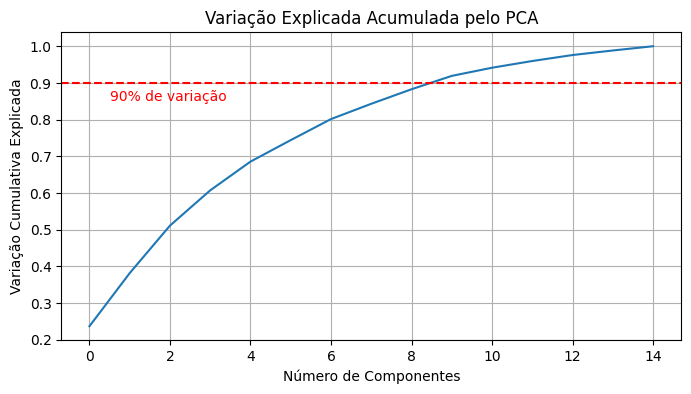

In [9]:
# Copiando variáveis necessárias
explainedVariance412 = explainedVariance

# Contribuição incremental de cada componente adicional e a identificar o ponto de cotovelo
plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(explainedVariance412))
plt.xlabel('Número de Componentes')
plt.ylabel('Variação Cumulativa Explicada')
plt.title('Variação Explicada Acumulada pelo PCA')
plt.axhline(y=0.90, color='r', linestyle='--')
plt.text(0.5, 0.85, '90% de variação', color = 'red')
plt.grid(True)
plt.show()


#### **4.1.3 - Análise Gráfica - Variação Explicada**



Este gráfico é uma ferramenta valiosa para entender como o PCA pode ser utilizado para identificar e priorizar os componentes mais informativos dos dados, facilitando análises mais eficientes e focadas.

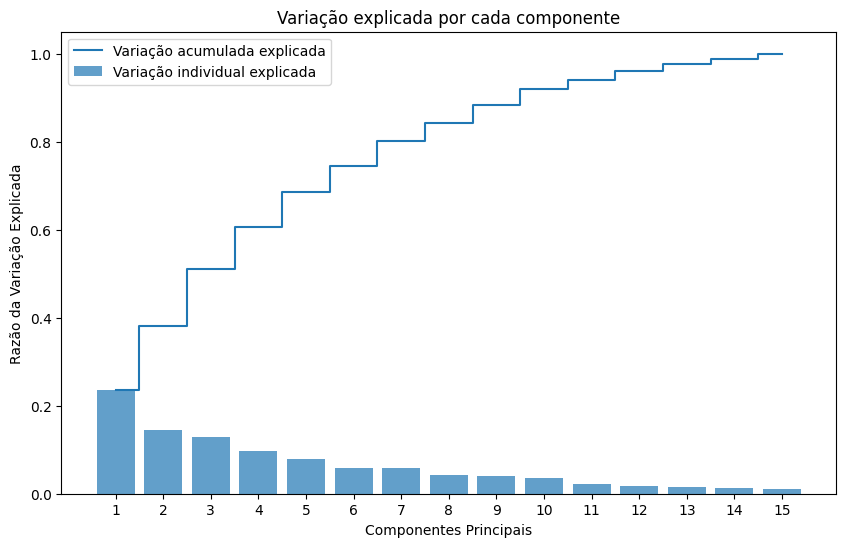

In [10]:
# Copiando variáveis necessárias
explainedVariance413 = explainedVariance
nComponents423 = nComponents

# Criando um gráfico de barras para a variação explicada por cada componente
plt.figure(figsize=(10, 6))
plt.bar(range(1, nComponents423+1), explainedVariance413, alpha=0.7, align='center', label='Variação individual explicada')
plt.step(range(1, nComponents423+1), np.cumsum(explainedVariance413), where='mid', label='Variação acumulada explicada')
plt.ylabel('Razão da Variação Explicada')
plt.xlabel('Componentes Principais')
plt.legend(loc='best')
plt.xticks(range(1, nComponents423+1))
plt.title('Variação explicada por cada componente')
plt.show()

### **4.2 - Número Ideal de Clusters - Elbow Method**

Para determinar o número ideial de clusters utilizamos o método do cotovelo (elbow method). Esta técnica envolve a execução do algoritmo k-means para um intervalo de valores de k (número de clusters) e, em seguida, para cada valor de k, calcular a soma dos quadrados intra-cluster (WCSS).

#### **4.2.1 - Aplicação do Elbow Method**

In [11]:
# Copiando variáveis necessárias
df421 = dfPCA.copy()

# Determina o número ideal de clusters usando o método do cotovelo
wcss = []
maxClusters = 15
for i in range(1, maxClusters+1):
    kmeans = KMeans(n_clusters=i, init='k-means++', n_init=10, random_state=42)

    kmeans.fit(df421)
    wcss.append(kmeans.inertia_)

# Criando um DataFrame com a quantidade de clusters e WCSS
resultWCSS = pd.DataFrame({'Number of Clusters': range(1, maxClusters + 1), 'WCSS': wcss})

# Exibindo o DataFrame
print(resultWCSS.to_string(index=False))

 Number of Clusters         WCSS
                  1 84149.130957
                  2 64408.000605
                  3 55322.831173
                  4 47163.699246
                  5 42092.054148
                  6 37821.747224
                  7 35134.436213
                  8 32684.657598
                  9 30156.997061
                 10 28708.688825
                 11 27100.833344
                 12 25664.576302
                 13 24363.526471
                 14 23501.181956
                 15 22237.543214


#### **4.2.2 - Análise Gráfica Elbow Method**

Este tipo de gráfico é extremamente útil, pois a partir dele identificamos o declínio da WCSS onde ela começa a diminuir mais lentamente, formando um "cotovelo". Este ponto representa um equilíbrio entre minimizar a distância dentro dos clusters e maximizar o número de clusters, indicando um número de clusters que poderia ser considerado ótimo para os dados.

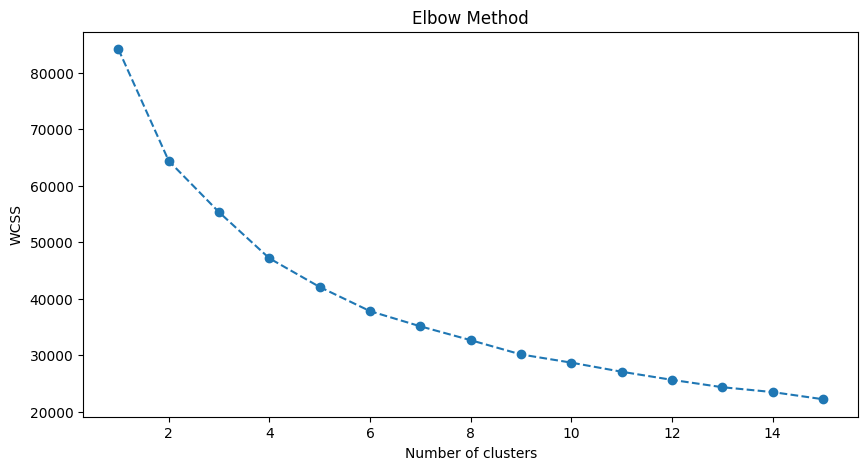

In [12]:
# Copiando variáveis necessárias
wcss422 = wcss.copy()
maxClusters422 = maxClusters

# Plotando os valores WCSS
plt.figure(figsize=(10,5))
plt.plot(range(1, maxClusters422+1), wcss422, marker='o', linestyle='--')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

### **4.3 - Algoritmo K-Means**

Nesta etapa, o objetivo é aplicar o algoritmo de agrupamento K-means aos dados transformados pela Análise de Componentes Principais (PCA) com o intuito de identificar grupos de indivíduos com perfis semelhantes de comorbidades. O K-means é um algoritmo de aprendizado não supervisionado que busca particionar os dados em um número pré-definido de grupos (clusters), de forma que os pontos dentro de cada cluster sejam o mais semelhantes possível e os pontos de diferentes clusters sejam o mais diferentes possível.

#### **4.3.1 - Aplicação do K-Means**

In [13]:
# Copiando variáveis necessárias
df431 = dfPCA.copy()

# Aplica agrupamento k-means com parâmetros refinados
nClusters = 6
kmeans = KMeans(n_clusters=nClusters, init='k-means++', n_init=50, max_iter=1000, random_state=42)
clusters = kmeans.fit_predict(df431)

# Converte clusters para uma Series do pandas e conta a quantidade de linhas em cada cluster
clusterCounts = pd.Series(clusters).value_counts()

# Imprime o resultado
print(clusterCounts)

1    40569
2    11585
5    11245
3     8523
4     8415
0     7341
Name: count, dtype: int64


#### **4.3.2 - Definindo os Clusters na Base**

In [14]:
# Copiando variáveis necessárias diretamente e adicionando a coluna 'Cluster'
dfClusteredB = dfGeralB.copy()
dfClusteredB['Cluster'] = clusters

dfClusteredR = dfGeralR.copy()
dfClusteredR['Cluster'] = clusters

# Exibindo as primeiras linhas dos DataFrames com os clusters
display(dfClusteredB.head())
display(dfClusteredR.head())

,Cadastro UBS,Agente Comunitário,Ler e Escrever,Escola,Trabalha,Plano de Saúde,Serviço de Saúde,Internação,Álcool,Exercício Físico,...,Grupo Artrite,Grupo DORT,Grupo Mental,Grupo Depressão,Grupo Pulmonar,Grupo Renal,Grupo Oncológico,Obesidade,Peso Amostral,Cluster
0,1,1,1,0,1,0,0,0,0,1,...,1,0,0,1,0,0,0,0,9.000088e-09,0
1,1,0,1,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,9.000087e-09,1
2,1,1,1,0,1,0,0,0,1,0,...,0,0,0,0,0,0,0,1,9.000087e-09,5
3,1,0,0,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,9.000087e-09,1
4,1,0,1,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,9.000087e-09,1


,UF,Zona,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Sexo,Idade,Raça,Estado Civil,...,Grupo Artrite,Grupo DORT,Grupo Mental,Grupo Depressão,Grupo Pulmonar,Grupo Renal,Grupo Oncológico,Grupo Cardiovascular,IMC,Cluster
0,1,1,1,2,1,1,2,55,1,2,...,1,0,0,1,0,0,0,1,28.537455,0
1,1,1,3,2,1,0,2,19,4,1,...,0,0,0,0,0,0,0,0,28.133657,1
2,1,1,4,3,1,1,2,45,3,1,...,0,0,0,0,0,0,0,0,32.049948,5
3,1,1,0,2,1,0,2,58,3,3,...,0,0,0,0,0,0,0,0,22.151023,1
4,1,1,5,1,1,0,2,28,4,1,...,0,0,0,0,0,0,0,0,17.755682,1


### **4.4 - Verificação da Distrubuição dos Clusters - Silhouette Analysis**

A Análise de Silhueta é uma técnica de interpretação e validação de consistência dentro dos clusters de dados. Ela fornece uma maneira de avaliar graficamente o quão bem cada objeto foi classificado em seu cluster durante o algoritmo de clusterização, como o K-means.

O coeficiente de Silhueta varia de -1 a +1, onde um valor alto indica que a amostra está bem ajustada ao seu próprio cluster e mal ajustada a clusters vizinhos. Se muitas amostras têm um valor alto, então a configuração de cluster é apropriada. Se muitas amostras têm um valor baixo ou negativo, então as amostras podem ter sido atribuídas ao cluster errado.

#### **4.4.1 - Aplicação da Silhouette Analysis - Score**

In [15]:
# Copiando variáveis necessárias
df441 = dfPCA.copy()
clusters441 = clusters.copy()

# O silhouette_score dá a média do valor para todos os samples
silhouetteScore = silhouette_score(df441, clusters441)

print(silhouetteScore)

0.5126871295516148


#### **4.4.2 - Aplicação da Silhouette Analysis - Samples**

In [16]:
# Copiando variáveis necessárias
df442 = dfPCA.copy()
clusters442 = clusters.copy()

# Calcula os coeficientes de Silhouette para cada ponto
silhouetteSamples = silhouette_samples(df442, clusters442)

# Criando um DataFrame com os valores de Silhouette e os rótulos de cluster
resultSilhouetteSamples = pd.DataFrame({
    'Silhouette Value': silhouetteSamples,
    'Cluster Label': clusters442
})

# Exibindo o DataFrame criado
resultSilhouetteSamples.head()

,Silhouette Value,Cluster Label
0,0.157689,0
1,0.871167,1
2,0.525265,5
3,0.871167,1
4,0.871167,1


#### **4.4.3 - Análise Gráfica - Silhouette**

 *   O gráfico de silhueta ajuda a avaliar a qualidade dos clusters formados, fornecendo uma visão rápida de como cada ponto se encaixa dentro de seu cluster. Essas visualizações são cruciais para a otimização do modelo de clustering, pois indicam se o número de clusters escolhido é apropriado e se a distribuição dos clusters faz sentido com base na variabilidade dos dados.

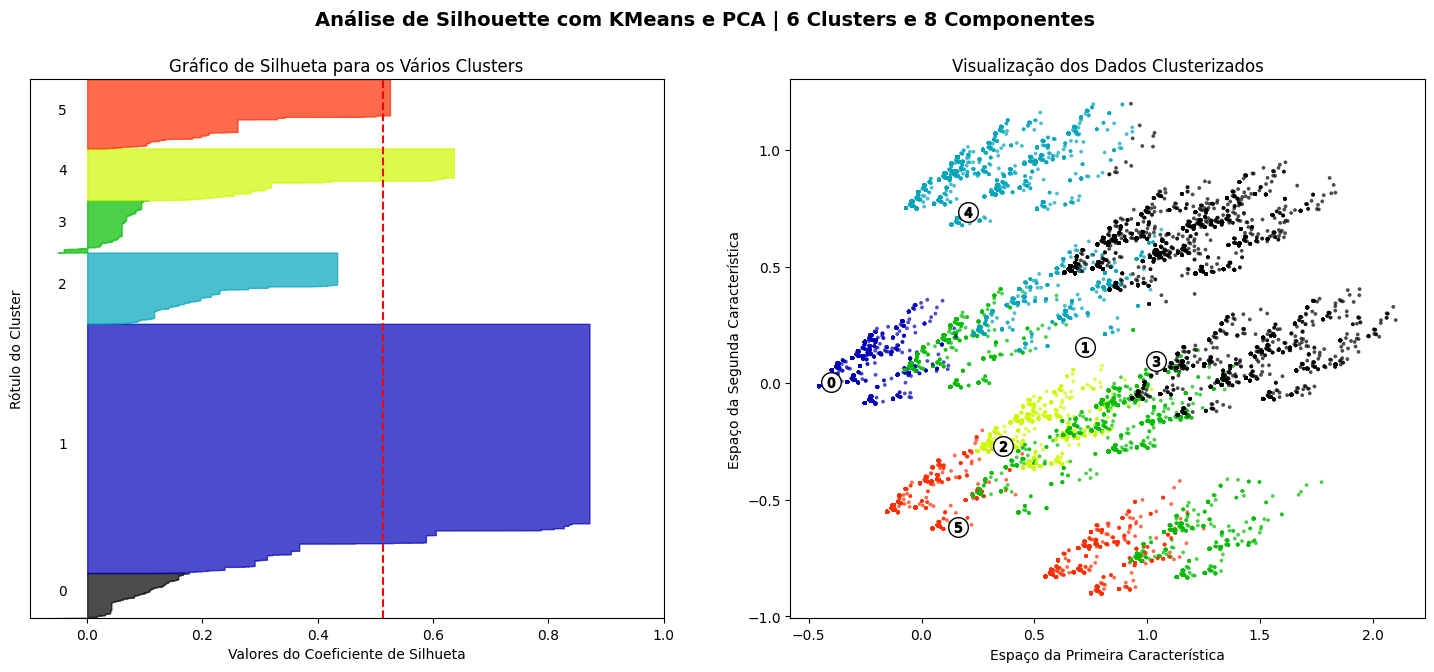

In [17]:
# Copiando variáveis necessárias
nClusters443 = nClusters
nComponents443 = nComponentsFinal
df443 = dfPCA.copy()
clusters443 = clusters.copy()
silhouetteScore443 = silhouetteScore
silhouetteSamples443 = silhouetteSamples

# Preparar o subplot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Definir limites para o gráfico de silhueta
ax1.set_xlim([-0.1, 1])
ax1.set_ylim([0, len(df443) + (nClusters443 + 1) * 10])

# Plotar o gráfico de silhueta
y_lower = 10
for i in range(nClusters443):
    ith_values = silhouetteSamples443[clusters443 == i]
    ith_values.sort()
    size_i = ith_values.shape[0]
    y_upper = y_lower + size_i

    color = cm.nipy_spectral(float(i) / nClusters443)
    ax1.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_values, facecolor=color, edgecolor=color, alpha=0.7)
    ax1.text(-0.05, y_lower + 0.5 * size_i, str(i))
    y_lower = y_upper + 10  # space between silhouettes

ax1.set_title("Gráfico de Silhueta para os Vários Clusters")
ax1.set_xlabel("Valores do Coeficiente de Silhueta")
ax1.set_ylabel("Rótulo do Cluster")
ax1.axvline(x=silhouetteScore443, color="red", linestyle="--")
ax1.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
ax1.set_yticks([])  # Limpar yticks para simplificar

# Plotar os dados clusterizados
colors = cm.nipy_spectral(clusters443.astype(float) / nClusters443)
ax2.scatter(df443[:, 0], df443[:, 1], marker='.', s=30, lw=0, alpha=0.7, c=colors, edgecolor='k')
centers = KMeans(n_clusters=nClusters443).fit(df443).cluster_centers_
ax2.scatter(centers[:, 0], centers[:, 1], marker='o', c="white", alpha=1, s=200, edgecolor='k')
for i, c in enumerate(centers):
    ax2.scatter(c[0], c[1], marker='$%d$' % i, alpha=1, s=50, edgecolor='k')

ax2.set_title("Visualização dos Dados Clusterizados")
ax2.set_xlabel("Espaço da Primeira Característica")
ax2.set_ylabel("Espaço da Segunda Característica")

plt.suptitle(f"Análise de Silhouette com KMeans e PCA | {nClusters443} Clusters e {nComponents443} Componentes", fontsize=14, fontweight='bold')
plt.show()

### **4.5 - Análise Descritiva - PCA, Elbow Method e Silhouette**

**PCA:**

A análise de componentes principais (PCA) mostra que os 10 primeiros componentes são suficientes para capturar mais de 90% da variação total, sugerindo que eles retêm a maioria das características essenciais dos dados. Utilizar esses 10 componentes permite uma redução significativa na complexidade dos dados sem perda considerável de informações, sendo uma escolha eficaz dependendo do nível de precisão desejado para o contexto específico da análise.

\\
**Elbow Method:**

O método do cotovelo indica que o número ótimo de clusters pode estar entre 4 e 6, baseado no ponto onde a redução no WCSS (soma dos quadrados das distâncias dentro dos clusters) se torna menos pronunciada. O maior declínio na taxa de redução do WCSS é observado até 6 clusters, com ganhos marginais além disso, sugerindo que 4 clusters podem ser suficientes para uma segmentação eficiente.

\\
**Silhouette Analysis:**

Foram realizados 20 testes variando de 8 a 12 componentes e de 3 a 6 clusters. A análise de silhueta indica que a configuração com 6 clusters e 10 componentes principais é a ideal, mostrando os maiores scores de silhueta. Essa combinação sugere boa separação e coerência interna dos clusters, preservando uma quantidade substancial das informações dos dados e proporcionando uma segmentação clara.

### **4.6 - Erro do Agrupamento**

O WCSS é uma medida da variabilidade dos pontos dentro de cada cluster, quanto menor o WCSS, mais densamente agrupados estão os pontos dentro de seus respectivos clusters. O erro médio por ponto dá uma ideia de quanto, em média, cada ponto difere do centro do cluster ao qual foi atribuído.

A soma dos quadrados intra-cluster (WCSS) do modelo k-means é aproximadamente 54.718,16 e o erro médio por ponto é 0.6240.

In [18]:
# Copiando variáveis necessárias
kmeans46 = kmeans
df46 = dfClusteredB.copy()

# Calcula o WCSS (inércia) para o agrupamento
wcssValue = kmeans46.inertia_

# Calcula o erro médio por ponto (inércia dividida pelo número de amostras)
erroMedioPorPonto = wcssValue / df46.shape[0]

# Exibe o erro médio por ponto
print(f'dispersão dos pontos de dados: {wcssValue}')
print(f'Erro médio por ponto: {erroMedioPorPonto}')

dispersão dos pontos de dados: 37821.74722433024
Erro médio por ponto: 0.4313710078278501


## **Etapa 5 - Consolidação dos Dados**

Nesta etapa, procedemos à consolidação e a exportação dos dados, que agora incorpora a coluna cluster.

### **5.1 - Análise da Média de Cada Atributo por Cluster**

Cria um dataframe com a média de cada atributo distribuída por clusters. Essas informações podem ser úteis para entender as características predominantes em cada cluster.

In [19]:
# Copiando variáveis necessárias
df51 = dfClusteredB.copy()

# Calcula a média de cada atributo por cluster
dfClusterMeans = df51.groupby('Cluster').mean()

# Mostra as medias dos clusters
dfClusterMeans.transpose()

Cluster,0,1,2,3,4,5
Cadastro UBS,6.853290e-01,6.114521e-01,6.509279e-01,6.311158e-01,6.629828e-01,6.299689e-01
Agente Comunitário,5.473369e-01,4.724790e-01,5.058265e-01,4.763581e-01,5.240642e-01,4.850156e-01
Ler e Escrever,7.993461e-01,9.176465e-01,8.732844e-01,8.735187e-01,8.187760e-01,9.124944e-01
Escola,2.629070e-02,1.013582e-01,6.189038e-02,4.646251e-02,3.065954e-02,6.536238e-02
Trabalha,3.188939e-01,6.136459e-01,5.508848e-01,4.524229e-01,3.819370e-01,5.813250e-01
...,...,...,...,...,...,...
Grupo Pulmonar,3.827816e-02,8.454731e-03,2.106172e-02,1.830341e-02,1.449792e-02,8.981770e-03
Grupo Renal,4.413568e-02,6.359536e-03,1.942167e-02,2.276194e-02,1.889483e-02,1.022677e-02
Grupo Oncológico,5.775780e-02,1.501146e-02,2.891670e-02,4.024405e-02,3.957219e-02,2.374389e-02
Obesidade,3.287018e-01,0.000000e+00,1.794562e-01,2.685674e-01,0.000000e+00,1.000000e+00


### **5.2 - Exportação dos Dados - Média de Atributo por Cluster**

Cria um dataframe com a média de cada atributo distribuída por clusters. Essas informações podem ser úteis para entender as características predominantes em cada cluster.

In [20]:
# Copiando variáveis necessárias
df52 = dfClusterMeans.copy()

# Criando um novo DataFrame para uso nessa célula
clusterMeansTranspose = df52.transpose()

# Resetar o índice para transformar o índice atual em uma coluna
clusterMeansTranspose.reset_index(inplace=True)

# Atribua novamente os nomes das colunas, agora incluindo o novo índice como coluna
nomes_colunas = ['Nome_do_Atributo', 'Cluster_0', 'Cluster_1', 'Cluster_2', 'Cluster_3', 'Cluster_4', 'Cluster_5']
clusterMeansTranspose.columns = nomes_colunas

# Exporta o DataFrame com as médias dos clusters para um arquivo XLSX
xlsx_file_path = 'PNS - Agrupamento - Médias.xlsx'
clusterMeansTranspose.to_excel(xlsx_file_path, index=True)

# Verifique se as mudanças foram aplicadas
clusterMeansTranspose.head()

,Nome_do_Atributo,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,Cluster_5
0,Cadastro UBS,0.685329,0.611452,0.650928,0.631116,0.662983,0.629969
1,Agente Comunitário,0.547337,0.472479,0.505826,0.476358,0.524064,0.485016
2,Ler e Escrever,0.799346,0.917646,0.873284,0.873519,0.818776,0.912494
3,Escola,0.026291,0.101358,0.061890,0.046463,0.030660,0.065362
4,Trabalha,0.318894,0.613646,0.550885,0.452423,0.381937,0.581325


### **5.3 - Exportação dos Dados - Clusters**

Nessa étapa, procedemos à exportação dos dados, que agora incluem uma coluna 'clusters'. Esta coluna é essencial para identificar a qual grupo ou categoria cada entrada do conjunto de dados pertence, baseado nos critérios de agrupamento previamente estabelecidos.

In [21]:
# Copiando variáveis necessárias
df53B = dfClusteredB.copy()
df53R = dfClusteredR.copy()

# Exporta o DataFrame com as médias dos clusters para um arquivo XLSX
xlsx_file_path_B = 'PNS - Agrupamento - Binários.xlsx'
xlsx_file_path_R = 'PNS - Agrupamento - Reais.xlsx'

df53B.to_excel(xlsx_file_path_B, index=True)
df53R.to_excel(xlsx_file_path_R, index=True)

## **Etapa 6 - Análises gráficas dos clusters**

Nesta parte efetuamos a plotagem e análise de gráficos referentes aos clusters gerados pelo algoritmo K-Means, com o intuito de interpretar e compreender as agrupações relacionadas a dor crônica na coluna identificadas na Pesquisa Nacional de Saúde de 2019.

### **6.1 - Mapa de Calor**

O mapa de calor é bastante útil para identificar rapidamente padrões e diferenças entre os clusters, facilitando a compreensão dos dados.

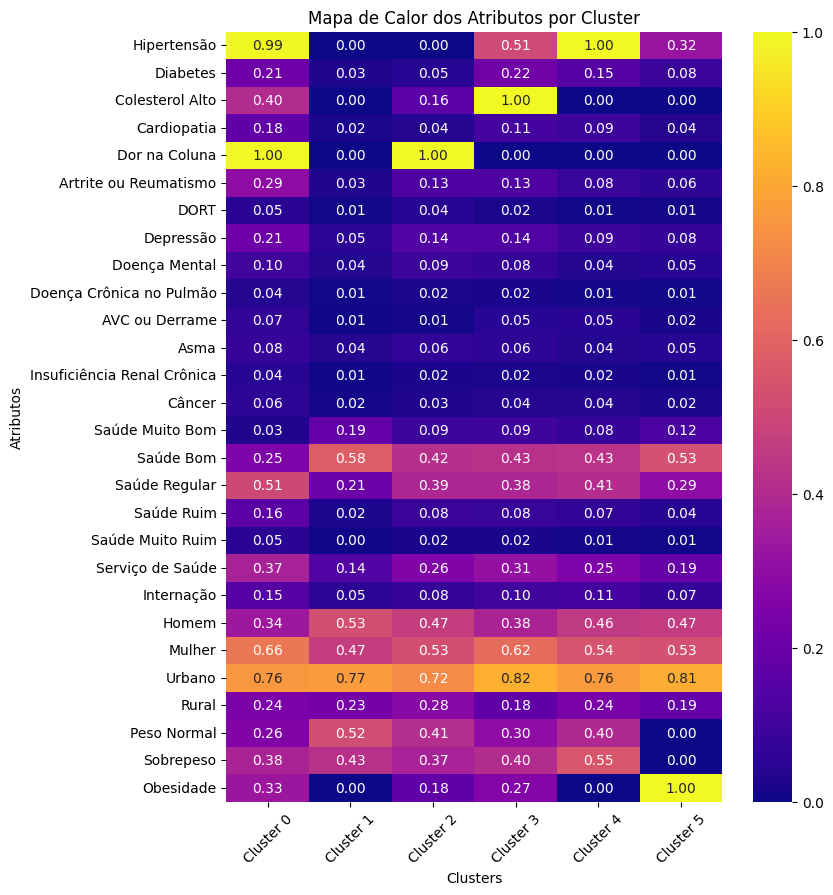

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Copiando variáveis necessárias
df61 = dfClusterMeans.copy()

# Selecionando colunas para o mapa de calor
atributos = [
  'Hipertensão',
  'Diabetes',
  'Colesterol Alto',
  'Cardiopatia',
  'Dor na Coluna',
  'Artrite ou Reumatismo',
  'DORT',
  'Depressão',
  'Doença Mental',
  'Doença Crônica no Pulmão',
  'AVC ou Derrame',
  'Asma',
  'Insuficiência Renal Crônica',
  'Câncer',
  'Saúde Muito Bom',
  'Saúde Bom',
  'Saúde Regular',
  'Saúde Ruim',
  'Saúde Muito Ruim',
  'Serviço de Saúde',
  'Internação',
  'Homem',
  'Mulher',
  'Urbano',
  'Rural',
  'Peso Normal',
  'Sobrepeso',
  'Obesidade'
]
dfHeatMap = df61[atributos].transpose()

# Ajustando o tamanho da figura para aumentar a altura das linhas
plt.figure(figsize=(8, 10))

# Criando o mapa de calor com a paleta de cores 'plasma'
ax = sns.heatmap(dfHeatMap, annot=True, cmap='plasma', fmt=".2f", linewidths=0, linecolor='white')
plt.title('Mapa de Calor dos Atributos por Cluster')
plt.xlabel('Clusters')
plt.ylabel('Atributos')

# Adicionando títulos para cada cluster
ax.set_xticklabels([f'Cluster {i}' for i in range(dfHeatMap.shape[1])])

plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()


### **6.2 - Diagrama de Radar**

O diagrama de radar é uma visualização de dados usada para exibir informações multivariadas de maneira bidimensional. É especialmente útil para comparar múltiplos itens ou casos em relação a várias características.

In [23]:
def gerar_diagrma_radar(df, attributes):

  fig = go.Figure()

  cluster_colors = ['lightcoral', 'skyblue', 'gold', 'limegreen', 'orchid', 'deepskyblue']

  for idx in df.index:
      fig.add_trace(go.Scatterpolar(
          r=df.loc[idx, attributes].values,
          theta=attributes,
          fill='toself',
          name=f'Cluster {idx}',
          hoverinfo='all',
          line=dict(color=cluster_colors[idx])
      ))

  fig.update_layout(
      polar=dict(
          radialaxis=dict(
              visible=True,
              range=[0, 1]
          )),
      showlegend=True,
      width=1000,
      height=800
  )

  fig.show()

# Copiando variáveis necessárias
df62 = dfClusterMeans.copy()

# Todos atributos
# atributos = df62.columns.drop('Cluster')
atributos = [
  'Hipertensão',
  'Diabetes',
  'Colesterol Alto',
  'Cardiopatia',
  'Dor na Coluna',
  'Artrite ou Reumatismo',
  'DORT',
  'Depressão',
  'Doença Mental',
  'Doença Crônica no Pulmão',
  'AVC ou Derrame',
  'Asma',
  'Insuficiência Renal Crônica',
  'Câncer',
  'Saúde Muito Bom',
  'Saúde Bom',
  'Saúde Regular',
  'Saúde Ruim',
  'Saúde Muito Ruim',
  'Serviço de Saúde',
  'Internação',
  'Homem',
  'Mulher',
  'Urbano',
  'Rural',
  'Peso Normal',
  'Sobrepeso',
  'Obesidade'
]

# Plotando Radar
gerar_diagrma_radar(df62, atributos)

### **6.3 - Gráficos de Barras**

O Grafico de Barras para comparativo entre clusters é uma maneira eficiente de visualizar as distribuições de um atributo específico entre diferentes grupos.

In [24]:
def gerar_grafico_barras_interativo(df, lista_de_atributos):

    data_frames = {attr: df.assign(Porcentagem=df[attr] * 100) for attr in lista_de_atributos}

    fig = go.Figure()

    cluster_colors = {0: 'lightcoral', 1: 'skyblue', 2: 'gold', 3: 'limegreen', 4: 'orchid', 5: 'deepskyblue'}

    for idx, atributo in enumerate(lista_de_atributos):
        data_frame = data_frames[atributo]

        # Mapeia cada índice (cluster) a uma cor
        cores_das_barras = [cluster_colors[i] for i in data_frame.index]

        fig.add_trace(
            go.Bar(
                x=data_frame.index.astype(str),
                y=data_frame['Porcentagem'],
                name=atributo,
                visible=True if idx == 0 else False,
                text=[f"{val:.0f}%" for val in data_frame['Porcentagem']],
                textposition='outside',
                marker_color=cores_das_barras
            )
        )

    botões = [{
        'label': atributo,
        'method': 'update',
        'args': [{'visible': [i == idx for i in range(len(lista_de_atributos))]},
                 {'title': f'Média de {atributo} por Cluster',
                  'yaxis': {'title': 'Média (%)', 'tickformat': ',.0f%'}}]
    } for idx, atributo in enumerate(lista_de_atributos)]

    fig.update_layout(
        updatemenus=[{
            'x': 0.5,     # Centralizado horizontalmente
            'xanchor': 'center',
            'y': 1.05,    # Um pouco abaixo do topo
            'yanchor': 'top',
            'buttons': botões,
            'showactive': True
        }],
        title=f'Porcentagem de {lista_de_atributos[0]} por Cluster',
        xaxis_title='Cluster',
        xaxis={'type': 'category'},
        yaxis={'title': 'Prcentagem (%)', 'tickformat': ',.0f%'},
        height=950,
        showlegend=False
    )

    fig.show()

# Copiando variáveis necessárias
df63 = dfClusterMeans.copy()

# Todos atributos
# atributos = df63.columns.drop('Cluster')
atributos = [
  'Hipertensão',
  'Diabetes',
  'Colesterol Alto',
  'Cardiopatia',
  'Dor na Coluna',
  'Artrite ou Reumatismo',
  'DORT',
  'Depressão',
  'Doença Mental',
  'Doença Crônica no Pulmão',
  'AVC ou Derrame',
  'Asma',
  'Insuficiência Renal Crônica',
  'Câncer',
  'Saúde Muito Bom',
  'Saúde Bom',
  'Saúde Regular',
  'Saúde Ruim',
  'Saúde Muito Ruim',
  'Serviço de Saúde',
  'Internação',
  'Plano de Saúde',
  'Homem',
  'Mulher',
  'Urbano',
  'Rural',
  'Peso Normal',
  'Sobrepeso',
  'Obesidade'
]

# Gerando grafico de barras interativo
gerar_grafico_barras_interativo(df63, atributos)

### **6.4 - Gráficos de Bolhas**


Gráficos de Bolhas ajuda na análise exploratória de dados, permitindo a visualização simultânea de múltiplas dimensões e a identificação rápida de padrões, relações e outliers em conjuntos de dados complexos, especialmente em cenários de clusterização, facilitando a tomada de decisões baseadas em dados.

In [25]:
def plot_bubble_chart_interactive(df, y_attrs, x_attrs, cluster_col='Cluster'):

    unique_clusters = sorted(df[cluster_col].unique())
    fig = go.Figure()

    y_spacing = 0.6
    bubble_spacing = 0.6
    cluster_colors = ['lightcoral', 'skyblue', 'gold', 'limegreen', 'orchid', 'deepskyblue']

    y_positions = {}
    y_attrs_duplicated = [f"{attr} - Sim" for attr in y_attrs] + [f"{attr} - Não" for attr in y_attrs]

    for i, y_attr in enumerate(y_attrs_duplicated):
        y_positions[y_attr] = i * (len(unique_clusters) * bubble_spacing + y_spacing)

    for cluster in unique_clusters:
        df_filtered = df[df[cluster_col] == cluster]
        data = []
        for y_attr in y_attrs:
            for x_attr in x_attrs:
                # Interseção positiva - Sim
                count_pos = len(df_filtered[(df_filtered[y_attr] == 1) & (df_filtered[x_attr] == 1)])
                y_pos_pos = y_positions[f"{y_attr} - Sim"] + cluster * bubble_spacing
                data.append({'y': y_pos_pos, 'x': x_attr, 'size': count_pos, 'cluster': cluster, 'intersection': '- Sim'})

                # Interseção negativa - Não
                count_neg = len(df_filtered[(df_filtered[y_attr] == 0) & (df_filtered[x_attr] == 1)])
                y_pos_neg = y_positions[f"{y_attr} - Não"] + cluster * bubble_spacing
                data.append({'y': y_pos_neg, 'x': x_attr, 'size': count_neg, 'cluster': cluster, 'intersection': '- Não'})

        df_plot = pd.DataFrame(data)

        # Criando um Scatter plot para cada cluster
        fig.add_trace(go.Scatter(
            x=df_plot['x'],
            y=df_plot['y'],
            mode='markers+text',
            marker=dict(
                size=df_plot['size'],
                sizemode='area',
                sizeref=1.*max(df_plot['size'])/(40.**2),
                color=cluster_colors[cluster],
                opacity=0.5
            ),
            text='<b>' + df_plot['size'].astype(str) + '</b>',
            textposition='middle center',
            textfont=dict(color='black'),
            hovertemplate='<b>%{x}</b><br><b>%{y}</b><br>Tamanho: %{text}<br>Cluster: %{marker.color}<br>Interseção: %{intersection}',
            name=f'Cluster {cluster}',
        ))

    # Ajustando o layout do gráfico
    fig.update_layout(
        title='Gráfico de Bolhas por Cluster - Quantidade',
        xaxis=dict(
            tickmode='array',
            tickvals=x_attrs,
            ticktext=x_attrs,
            showgrid=False,
            zeroline=False
        ),
        yaxis=dict(
            tickmode='array',
            tickvals=[y_positions[attr] + (len(unique_clusters) - 1) * bubble_spacing / 2 for attr in y_attrs_duplicated],
            ticktext=y_attrs_duplicated,
            showgrid=False,
            zeroline=False
        ),
        height=150 + 80 * (len(y_attrs_duplicated) * (len(unique_clusters) * bubble_spacing + y_spacing) - y_spacing),
        width=200 + 200 * len(x_attrs),
        showlegend=True
    )

    fig.show()

# Copiando variáveis necessárias
df64 = dfClusteredB.copy()

# Todos atributos
atributos_Y = [
    "Serviço de Saúde",
    #"Internação"
    #"Plano de Saúde",
]

atributos_X = [
    "Saúde Muito Bom",
    "Saúde Bom",
    "Saúde Regular",
    "Saúde Ruim",
    "Saúde Muito Ruim"
]

# Gerando gráfico de dispersão interativo
plot_bubble_chart_interactive(df64, atributos_Y, atributos_X)

In [26]:
def plot_bubble_chart_interactive(df, y_attrs, x_attrs, cluster_col='Cluster'):
    cluster_colors = ['lightcoral', 'skyblue', 'gold', 'limegreen', 'orchid', 'deepskyblue']
    unique_clusters = sorted(df[cluster_col].unique())

    fig = go.Figure()

    # Definindo um espaçamento fixo para o eixo Y e entre as bolhas
    y_spacing = 1.0
    bubble_spacing = 0.6

    y_positions = {}
    y_attrs_duplicated = [f"{attr} - Sim" for attr in y_attrs] + [f"{attr} - Não" for attr in y_attrs]

    for i, y_attr in enumerate(y_attrs_duplicated):
        y_positions[y_attr] = i * (len(unique_clusters) * bubble_spacing + y_spacing)

    for cluster in unique_clusters:
        total_count = len(df)
        df_filtered = df[df[cluster_col] == cluster]
        #total_count = len(df_filtered)
        data = []
        for y_attr in y_attrs:
            for x_attr in x_attrs:
                # Interseção positiva - Sim
                count_pos = len(df_filtered[(df_filtered[y_attr] == 1) & (df_filtered[x_attr] == 1)])
                percent_pos = (count_pos / total_count) * 100
                y_pos_pos = y_positions[f"{y_attr} - Sim"] + cluster * bubble_spacing
                data.append({'y': y_pos_pos, 'x': x_attr, 'size': percent_pos, 'cluster': cluster, 'intersection': '- Sim'})

                # Interseção negativa - Não
                count_neg = len(df_filtered[(df_filtered[y_attr] == 0) & (df_filtered[x_attr] == 1)])
                percent_neg = (count_neg / total_count) * 100
                y_pos_neg = y_positions[f"{y_attr} - Não"] + cluster * bubble_spacing
                data.append({'y': y_pos_neg, 'x': x_attr, 'size': percent_neg, 'cluster': cluster, 'intersection': '- Não'})

        df_plot = pd.DataFrame(data)

        # Criando um Scatter plot para cada cluster
        fig.add_trace(go.Scatter(
            x=df_plot['x'],
            y=df_plot['y'],
            mode='markers+text',
            marker=dict(
                size=df_plot['size'],
                sizemode='area',
                sizeref=1.*max(df_plot['size'])/(40.**2),
                color=cluster_colors[cluster],
                opacity=0.5
            ),
            text=df_plot['size'].apply(lambda x: f'<b>{x:.2f}%</b>'),
            textposition='middle center',
            textfont=dict(color='black'),
            hovertemplate='<b>%{x}</b><br><b>%{y}</b><br>Porcentagem: %{text}<br>Cluster: %{marker.color}<br>Interseção: %{intersection}',
            name=f'Cluster {cluster}',
        ))

    # Ajustando o layout do gráfico
    fig.update_layout(
        title='Gráfico de Bolhas por Cluster - Porcentagem',
        xaxis=dict(
            tickmode='array',
            tickvals=x_attrs,
            ticktext=x_attrs,
            showgrid=False,
            zeroline=False
        ),
        yaxis=dict(
            tickmode='array',
            tickvals=[y_positions[attr] + (len(unique_clusters) - 1) * bubble_spacing / 2 for attr in y_attrs_duplicated],
            ticktext=y_attrs_duplicated,
            showgrid=False,
            zeroline=False
        ),
        height=150 + 80 * (len(y_attrs_duplicated) * (len(unique_clusters) * bubble_spacing + y_spacing) - y_spacing),
        width=200 + 200 * len(x_attrs),
        showlegend=True,
        legend=dict(itemsizing='constant')
    )

    fig.show()

# Copiando variáveis necessárias
df64 = dfClusteredB.copy()

# Todos atributos
atributos_Y = [
    "Serviço de Saúde",
    #"Internação"
    #"Plano de Saúde",
]

atributos_X = [
    "Saúde Muito Bom",
    "Saúde Bom",
    "Saúde Regular",
    "Saúde Ruim",
    "Saúde Muito Ruim"
]

# Gerando gráfico de dispersão interativo
plot_bubble_chart_interactive(df64, atributos_Y, atributos_X)

total_count = len(df64)
print(f"Total de registros: {total_count}")
cluster_counts = df64['Cluster'].value_counts()
print(cluster_counts)

Total de registros: 87678
Cluster
1    40569
2    11585
5    11245
3     8523
4     8415
0     7341
Name: count, dtype: int64


## **Etapa 7 - Análise descritiva dos Clusters**

Nesta etapa é realizada a análise descritiva dos Clusters 0, 1, 2 e 3, com base no agrupamento realizado e análises gráficas realizadas. Que revela uma série de diferenças marcantes que refletem as diversas necessidades de saúde, padrões de vida e características demográficas.

### **7.1 - Análise Cluster 0**

O Cluster 0 retrata uma população com bom acesso aos serviços de saúde básicos, uma alta taxa de emprego e um nível educacional satisfatório. No entanto, enfrenta desafios significativos relacionados à obesidade e suas comorbidades, como hipertensão, diabetes e problemas cardiovasculares. As condições de saúde mental também são preocupantes e podem estar interligadas com o estado de saúde físico. Estratégias de saúde pública direcionadas para redução da obesidade, promoção de hábitos de vida mais saudáveis e melhor manejo das doenças crônicas são essenciais para melhorar a qualidade de vida deste grupo.

**Comorbidades:**
*   Dor na Coluna: 0.0%
*   Hipertensão: 37.20%
*   Diabetes: 11.39%
*   Colesterol Alto: 16.89%
*   Cardiopatia: 5.18%
*   AVC ou Derrame: 2.16%
*   Asma: 5.08%
*   Artrite ou Reumatismo: 7.07%
*   DORT: 1.68%
*   Depressão: 8.91%
*   Doença Mental: 5.12%
*   Doença Crônica no Pulmão: 1.08%
*   Câncer: 2.61%
*   Insuficiência Renal Crônica: 1.23%

**Estado de Saúde:**
*   Saúde Regular: 31.51%
*   Saúde Muito Ruim: 1.06%
*   Saúde Bom: 51.10%
*   Saúde Muito Bom: 11.22%
*   Saúde Ruim: 5.09%

**Demográficos:**
*   Urbano: 81.64%
*   Rural: 18.36%
*   Homem: 45.38%
*   Mulher: 54.62%

**Uso de Serviço de Saúde:**
*   Serviço de Saúde: 21.03%

**Faixa Etária:**
*   Idade 18 a 29: 12.97%
*   Idade 30 a 39: 24.16%
*   Idade 40 a 49: 22.43%
*   Idade 50 a 59: 18.57%
*   Idade 60 a 69: 13.89%
*   Idade 70 a 79: 6.16%
*   Idade 80 a 89: 1.58%
*   Idade 90 a 99: 0.23%
*   Idade 100 a 104: 0.0%

**Índice de Massa Corporal (IMC):**
*   Peso Normal: 0.0%
*   Sobrepeso: 0.0%
*   Obesidade: 100.0%

### **7.2 - Análise Cluster 1**

O Cluster 1 representa uma população com bom acesso a serviços de saúde básicos, mas enfrenta desafios críticos relacionados à saúde cardiovascular, especialmente hipertensão e colesterol alto. A alta prevalência de diabetes também contribui para o risco de complicações graves. A distribuição etária mais velha pode influenciar a prevalência dessas condições crônicas. Embora a obesidade não seja um problema extremo neste cluster, o sobrepeso é significativo e deve ser abordado através de intervenções nutricionais e de atividade física. Estratégias de saúde pública focadas no manejo de hipertensão, diabetes e saúde cardiovascular são essenciais para melhorar a qualidade de vida desta população.

**Comorbidades:**
*   Dor na Coluna: 0.0%
*   Hipertensão: 99.99%
*   Diabetes: 19.13%
*   Colesterol Alto: 26.01%
*   Cardiopatia: 10.91%
*   AVC ou Derrame: 5.87%
*   Asma: 3.94%
*   Artrite ou Reumatismo: 10.03%
*   DORT: 1.24%
*   Depressão: 10.49%
*   Doença Mental: 4.46%
*   Doença Crônica no Pulmão: 1.63%
*   Câncer: 4.24%
*   Insuficiência Renal Crônica: 2.25%

**Estado de Saúde:**
*   Saúde Regular: 42.12%
*   Saúde Muito Ruim: 1.60%
*   Saúde Bom: 41.16%
*   Saúde Muito Bom: 7.30%
*   Saúde Ruim: 7.82%

**Demográficos:**
*   Urbano: 77.52%
*   Rural: 22.48%
*   Homem: 42.76%
*   Mulher: 57.24%

**Uso de Serviço de Saúde:**
*   Serviço de Saúde: 27.45%

**Faixa Etária:**
*   Idade 18 a 29: 2.96%
*   Idade 30 a 39: 6.78%
*   Idade 40 a 49: 13.13%
*   Idade 50 a 59: 21.12%
*   Idade 60 a 69: 26.23%
*   Idade 70 a 79: 20.35%
*   Idade 80 a 89: 8.03%
*   Idade 90 a 99: 1.34%
*   Idade 100 a 104: 0.06%

**Índice de Massa Corporal (IMC):**
*   Peso Normal: 39.04%
*   Sobrepeso: 55.97%
*   Obesidade: 0.0%

### **7.3 - Análise Cluster 2**

O Cluster 2 representa uma população jovem, ativa e empregada, com um perfil de saúde relativamente bom e equilibrado. A ausência de hipertensão e a baixa prevalência de doenças crônicas são aspectos positivos, provavelmente influenciados pelos altos níveis de atividade física e menor consumo de tabaco. No entanto, a saúde mental continua sendo uma área de preocupação, embora em menor escala. As estratégias de saúde pública devem focar em manter e promover estilos de vida saudáveis, garantindo ao mesmo tempo o suporte adequado para questões de saúde mental e prevenindo o surgimento de doenças crônicas no futuro.

**Comorbidades:**
*   Dor na Coluna: 0.0%
*   Hipertensão: 0.0%
*   Diabetes: 3.44%
*   Colesterol Alto: 7.47%
*   Cardiopatia: 2.22%
*   AVC ou Derrame: 0.83%
*   Asma: 4.11%
*   Artrite ou Reumatismo: 3.22%
*   DORT: 1.08%
*   Depressão: 5.94%
*   Doença Mental: 4.14%
*   Doença Crônica no Pulmão: 0.89%
*   Câncer: 1.63%
*   Insuficiência Renal Crônica: 0.69%

**Estado de Saúde:**
*   Saúde Regular: 21.32%
*   Saúde Muito Ruim: 0.49%
*   Saúde Bom: 57.46%
*   Saúde Muito Bom: 18.25%
*   Saúde Ruim: 2.48%

**Demográficos:**
*   Urbano: 77.06%
*   Rural: 22.94%
*   Homem: 51.79%
*   Mulher: 48.21%

**Uso de Serviço de Saúde:**
*   Serviço de Saúde: 15.13%

**Faixa Etária:**
*   Idade 18 a 29: 25.64%
*   Idade 30 a 39: 25.29%
*   Idade 40 a 49: 19.20%
*   Idade 50 a 59: 14.44%
*   Idade 60 a 69: 9.10%
*   Idade 70 a 79: 4.30%
*   Idade 80 a 89: 1.70%
*   Idade 90 a 99: 0.31%
*   Idade 100 a 104: 0.02%

**Índice de Massa Corporal (IMC):**
*   Peso Normal: 51.63%
*   Sobrepeso: 43.23%
*   Obesidade: 0.0%

### **7.4 - Análise Cluster 3**

O Cluster 3 representa uma população com um perfil de saúde complexo, caracterizado por uma alta prevalência de condições crônicas como hipertensão, diabetes e problemas cardiovasculares. A presença significativa de problemas de saúde mental e obesidade exacerba os desafios de saúde deste grupo. Embora o acesso aos serviços básicos de saúde seja bom, a dependência dos serviços públicos e a baixa cobertura de planos de saúde privados podem limitar o acesso a cuidados especializados. Estratégias de saúde pública devem focar na redução da obesidade, promoção de hábitos de vida saudáveis, e fornecimento de suporte psicológico, além de um manejo integrado das condições crônicas para melhorar a qualidade de vida desta população.

**Comorbidades:**
*   Dor na Coluna: 100.0%
*   Hipertensão: 38.54%
*   Diabetes: 11.07%
*   Colesterol Alto: 25.52%
*   Cardiopatia: 9.45%
*   AVC ou Derrame: 3.40%
*   Asma: 6.86%
*   Artrite ou Reumatismo: 19.43%
*   DORT: 4.55%
*   Depressão: 16.79%
*   Doença Mental: 9.19%
*   Doença Crônica no Pulmão: 2.77%
*   Câncer: 4.01%
*   Insuficiência Renal Crônica: 2.90%

**Estado de Saúde:**
*   Saúde Regular: 43.47%
*   Saúde Muito Ruim: 3.13%
*   Saúde Bom: 35.45%
*   Saúde Muito Bom: 6.47%
*   Saúde Ruim: 11.48%

**Demográficos:**
*   Urbano: 73.54%
*   Rural: 26.46%
*   Homem: 41.99%
*   Mulher: 58.01%

**Uso de Serviço de Saúde:**
*   Serviço de Saúde: 29.92%

**Faixa Etária:**
*   Idade 18 a 29: 8.41%
*   Idade 30 a 39: 14.34%
*   Idade 40 a 49: 19.03%
*   Idade 50 a 59: 23.26%
*   Idade 60 a 69: 19.52%
*   Idade 70 a 79: 11.17%
*   Idade 80 a 89: 3.73%
*   Idade 90 a 99: 0.50%
*   Idade 100 a 104: 0.03%

**Índice de Massa Corporal (IMC):**
*   Peso Normal: 35.27%
*   Sobrepeso: 37.29%
*   Obesidade: 23.58%

### **7.5 - Análise entre os Clusters**

Os Clusters 0, 1, 2 e 3 apresentam perfis distintos de saúde e comportamentos, refletindo diferentes necessidades e desafios.

Cada cluster apresenta um conjunto único de desafios e características de saúde. O Cluster 0 é marcado pela obesidade extrema e suas comorbidades. O Cluster 1 destaca-se pela alta prevalência de hipertensão e problemas cardiovasculares. O Cluster 2, com uma população jovem e ativa, apresenta melhor perfil de saúde geral. O Cluster 3 combina uma alta prevalência de doenças crônicas e problemas de saúde mental, refletindo uma população de meia-idade e mais velha com necessidades complexas de saúde. Estratégias de saúde pública devem ser personalizadas para atender às necessidades específicas de cada cluster, focando na prevenção, manejo de condições crônicas e promoção de estilos de vida saudáveis.

**Correlações e Implicações:**

*   **Hipertensão e Saúde Cardiovascular**:
    
    A alta prevalência de hipertensão no Cluster 1 (99%) e no Cluster 3 (38%) correlaciona-se com altos níveis de colesterol e cardiopatia. O Cluster 2, com ausência de hipertensão e baixos níveis de colesterol e cardiopatia, destaca-se por um perfil de saúde cardiovascular mais favorável.

*   **Diabetes e Obesidade**:
    
    A obesidade extrema no Cluster 0 (100%) está fortemente correlacionada com a prevalência de diabetes e hipertensão. Clusters 1 e 3, com menores taxas de obesidade, têm níveis elevados de diabetes e problemas cardiovasculares, mas a obesidade não é tão prevalente quanto no Cluster 0.

*   **Saúde Mental**:

    Clusters 1 e 3 mostram uma alta prevalência de depressão e outras doenças mentais, indicando uma correlação entre problemas de saúde física e mental. O Cluster 3, com 16% de depressão, destaca-se particularmente.

*   **Distribuição Etária**:
    
    A predominância de faixas etárias mais jovens no Cluster 2 pode explicar a melhor saúde cardiovascular e menor incidência de doenças crônicas. Clusters 1 e 3, com populações mais velhas, mostram maior prevalência de condições crônicas e problemas de saúde mental.
